In [1]:
from google.colab import files
uploaded = files.upload()

Saving archive (4).zip to archive (4).zip


In [3]:
import zipfile
import os

# Extract the uploaded ZIP file
zip_path = "/content/archive (4).zip"
extract_path = "/content/employee_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Display extracted files
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

/content/employee_data/WA_Fn-UseC_-HR-Employee-Attrition.csv


In [4]:
import pandas as pd
import glob
import os

csv_files = glob.glob(
    "/content/employee_data/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

if csv_files:
    df = pd.read_csv(csv_files[0])

    print("\nDataset shape:", df.shape)
    display(df.head())
    df.info()
else:
    print("No CSV file found. Check the extracted file list above.")

CSV files found: ['/content/employee_data/WA_Fn-UseC_-HR-Employee-Attrition.csv']

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

Missing values: 0
Duplicate rows: 0
Attrition
No     1233
Yes     237
Name: count, dtype: int64


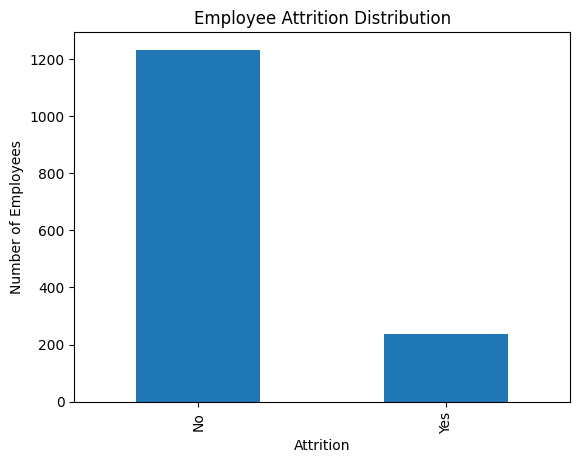

In [5]:
# Check missing values
print("Missing values:", df.isnull().sum().sum())

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check target distribution
print(df["Attrition"].value_counts())

# Visualize attrition
df["Attrition"].value_counts().plot(
    kind="bar",
    title="Employee Attrition Distribution"
)
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

In [6]:
df = df.drop(
    columns=["EmployeeCount", "EmployeeNumber",
             "Over18", "StandardHours"],
    errors="ignore"
)

# Convert target to binary values
df["Attrition"] = df["Attrition"].map(
    {"No": 0, "Yes": 1}
)

print(df["Attrition"].value_counts())
print("Updated shape:", df.shape)

Attrition
0    1233
1     237
Name: count, dtype: int64
Updated shape: (1470, 31)


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

X = df.drop(columns=["Attrition"])
y = df["Attrition"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocessing for numerical data
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical data
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1176
Testing records: 294


In [8]:
%pip install -q xgboost

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [10]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
1,Decision Tree,0.7551,0.2642,0.2979,0.2800,0.5700
2,Random Forest,0.8469,0.6250,0.1064,0.1818,0.7832
3,XGBoost,0.8571,0.6316,0.2553,0.3636,0.7965


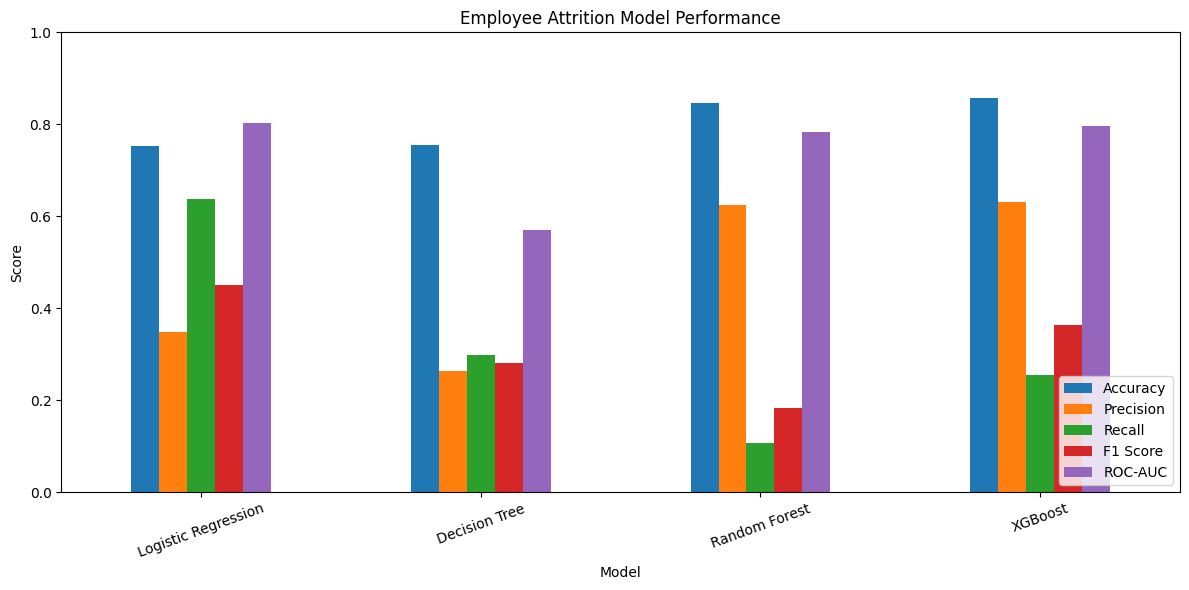

In [11]:
results_df.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    kind="bar",
    figsize=(12, 6)
)

plt.title("Employee Attrition Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



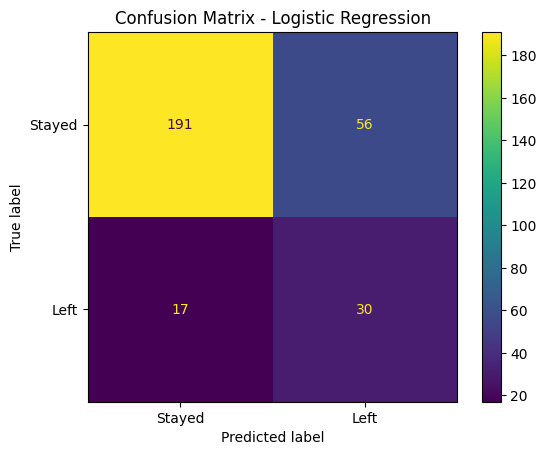


Decision Tree
              precision    recall  f1-score   support

      Stayed       0.86      0.84      0.85       247
        Left       0.26      0.30      0.28        47

    accuracy                           0.76       294
   macro avg       0.56      0.57      0.57       294
weighted avg       0.77      0.76      0.76       294



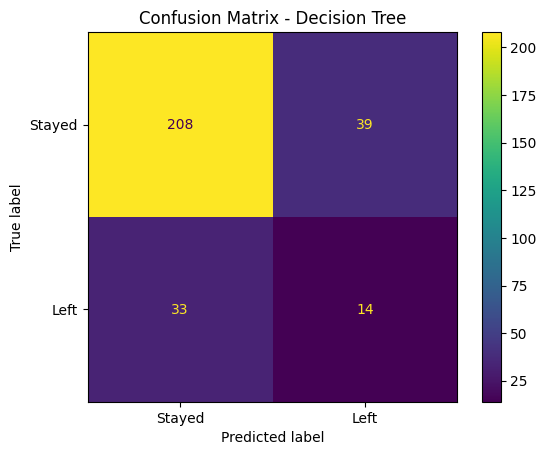


Random Forest
              precision    recall  f1-score   support

      Stayed       0.85      0.99      0.92       247
        Left       0.62      0.11      0.18        47

    accuracy                           0.85       294
   macro avg       0.74      0.55      0.55       294
weighted avg       0.82      0.85      0.80       294



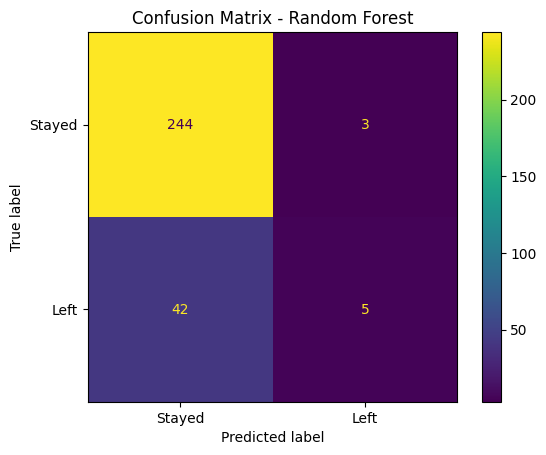


XGBoost
              precision    recall  f1-score   support

      Stayed       0.87      0.97      0.92       247
        Left       0.63      0.26      0.36        47

    accuracy                           0.86       294
   macro avg       0.75      0.61      0.64       294
weighted avg       0.83      0.86      0.83       294



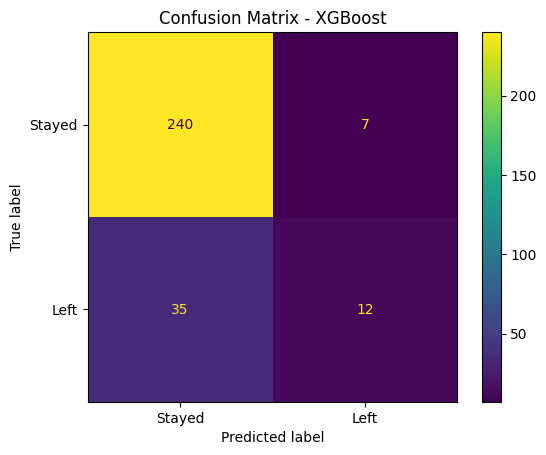

In [12]:
for name, pipeline in trained_models.items():
    predictions = pipeline.predict(X_test)

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        predictions,
        target_names=["Stayed", "Left"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Stayed", "Left"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

cv_results = []

for name, pipeline in trained_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.7534,0.3721,0.7368,0.4925,0.8273
1,Decision Tree,0.7789,0.3037,0.2684,0.2801,0.5728
2,Random Forest,0.8614,0.8762,0.1737,0.2835,0.8043
3,XGBoost,0.8699,0.7358,0.3053,0.4296,0.8122


In [14]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", grid_search.best_score_)

best_rf = grid_search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Best cross-validation F1: 0.3614363252243593


In [15]:
y_pred_tuned = best_rf.predict(X_test)
y_prob_tuned = best_rf.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Results")
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(
    y_test, y_pred_tuned, zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_tuned, zero_division=0
))
print("F1 Score:", f1_score(
    y_test, y_pred_tuned, zero_division=0
))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

Tuned Random Forest Results
Accuracy: 0.8299319727891157
Precision: 0.4117647058823529
Recall: 0.14893617021276595
F1 Score: 0.21875
ROC-AUC: 0.7930054268240159


,Feature,Importance
9,num__MonthlyIncome,0.080312
16,num__TotalWorkingYears,0.063196
0,num__Age,0.056106
1,num__DailyRate,0.046676
19,num__YearsAtCompany,0.045255
10,num__MonthlyRate,0.043380
5,num__HourlyRate,0.040012
22,num__YearsWithCurrManager,0.039317
2,num__DistanceFromHome,0.038799
11,num__NumCompaniesWorked,0.035192


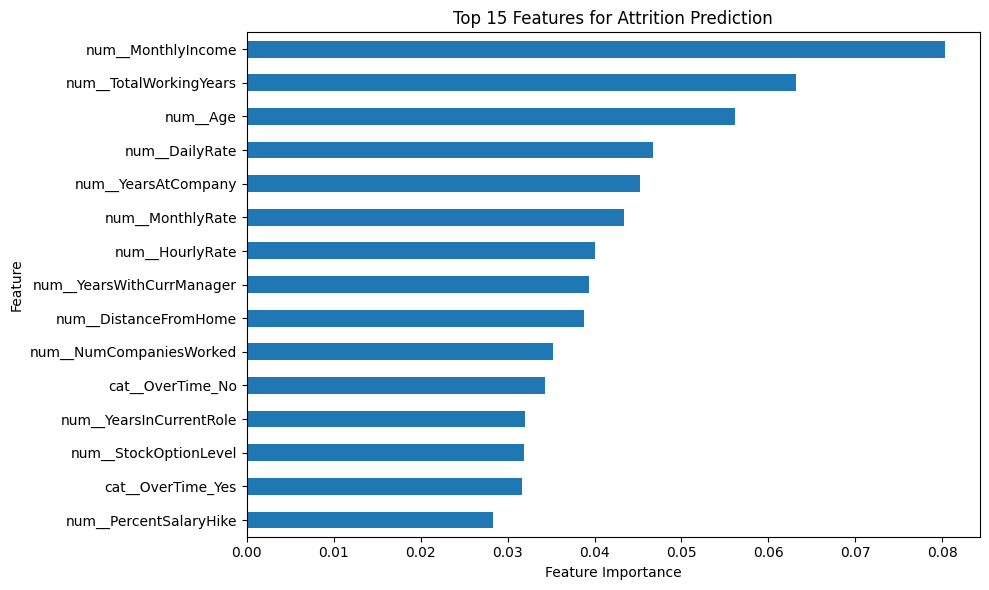

In [16]:
feature_names = best_rf.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = best_rf.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Features for Attrition Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [17]:
import os

os.makedirs("reports", exist_ok=True)
os.makedirs("models", exist_ok=True)

results_df.to_csv(
    "reports/model_evaluation.csv", index=False
)

cv_df.to_csv(
    "reports/cross_validation.csv", index=False
)

importance_df.to_csv(
    "reports/feature_importance.csv", index=False
)

print("Evaluation files saved successfully.")

Evaluation files saved successfully.


In [18]:
import joblib

joblib.dump(best_rf, "models/best_random_forest.joblib")

['models/best_random_forest.joblib']

In [19]:
from google.colab import files

files.download("reports/model_evaluation.csv")
files.download("reports/cross_validation.csv")
files.download("reports/feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>